# Lab 12: GRACE Ocean Mass and Global Mean Sea Level

In this lab, we will investigate the ocean mass contribution to sea level rise - the so-called "barystatic component" - using estimates from the Gravity Recovery and Climate Experiment (GRACE) and its follow-on (GRACE-FO).

**Learning Objectives**:

By the end of this lab, you should be able to
- obtain monthly GRACE/GRACE-FO mascon data and generate maps
- Estimate a time series of barystatic height from the GRACE data
- Estimate a time series of steric height from the altimetry and ocean mass data

**Import the modules for this notebook**

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import netCDF4 as nc4
from datetime import datetime, timedelta, date
import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature

## Motivation

In [Lab 10](https://profmikewood.github.io/ocean_remote_sensing_book/lab10-swot-pace/), we explored sea surface height from satellite altimeters that use radars to measure the ocean surface. Over time, these altimeters can be used to esimate global mean sea level rise. However, to diagnose the causes of sea level change, we need to partition *steric* change associated with changes in seawater volume and density as temperature and salinity vary, with *barystatic* change from changes in mass as water is added from land ice, groundwater, rivers, and other reservoirs, i.e.

$$
\eta'_{\text{total}} \approx \eta'_{\text{barystatic}} + \eta'_{\text{steric}}
$$


GRACE is one of the few satellite systems that lets us estimate the mass contribution from changes in Earth’s gravity field.

In this lab, we will use GRACE/GRACE-FO mascon data to estimate the ocean mass contribution to sea level rise. Then, we will compare this estimate to estimates of global sea level to estimate the steric height contribution.

## Getting Started

For this lab, we will use the [JPL GRACE/GRACE-FO](https://podaac.jpl.nasa.gov/dataset/TELLUS_GRAC-GRFO_MASCON_CRI_GRID_RL06.3_V4) mascon product. The product is distributed as a monthly global netCDF file containing liquid water equivalent thickness anomalies. The most recently-updated file can be downloaded from the link [HERE](https://archive.podaac.earthdata.nasa.gov/podaac-ops-cumulus-protected/TELLUS_GRAC-GRFO_MASCON_CRI_GRID_RL06.3_V4/GRCTellus.JPL.200204_202609.GLO.RL06.3M.MSCNv04CRI.nc).

Navigate to this link and download the `GRCTellus.JPL.200204_YYYYMM.GLO.RL06.3M.MSCNv04CRI.nc` file into your data folder for this lab (defined here):

In [2]:
data_folder = '../data/labs/lab12'

## Part 1: Reading and Visualizing the GRACE Mascon Data

In the space below, we'll read in the GRACE mascon dataset similar to our analysis with other netCDF datasets. Using the file downloaded above, import the following fields:
- the `lon`, `lat`, `lon_bounds`, `lat_bounds`,
- the `time` and `time_bounds` variables
- the liquid water equivalent thickness field
- the land mask 

In [3]:
# Read in the GRACE dataset
ds = nc4.Dataset(os.path.join(data_folder,'GRCTellus.JPL.200204_202609.GLO.RL06.3M.MSCNv04CRI.nc'))
lon = ds.variables['lon'][:]
lat = ds.variables['lat'][:]
lon_bounds = ds.variables['lon_bounds'][:, :]
lat_bounds = ds.variables['lat_bounds'][:, :]
days_since_2002 = ds.variables['time'][:]
days_since_2002_bounds = ds.variables['time_bounds'][:,:]
lwe_thickness = ds.variables['lwe_thickness'][:, :, :]
land_mask = ds.variables['land_mask'][:, :]
ds.close()

**&#x1F914; Check your units**
1. What are the units of the time variables?
2. What are the units of the liquid water equivalent thickness field?

After you've read in the data, use the space below to generate a map of one monthly liquid water equivalent thickness (any month is fine). Be sure to use a divergent colorbar and stretch the color axes so that it is centered on 0.

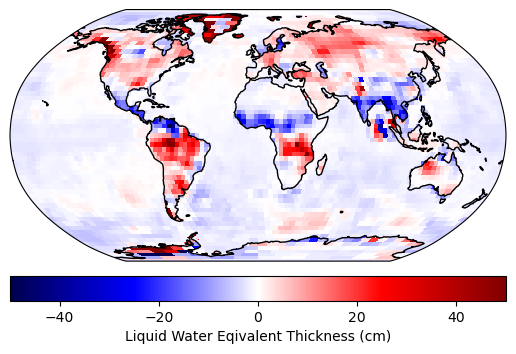

In [4]:
# make your figure here
fig=plt.figure()
proj = ccrs.Robinson()
ax1 = fig.add_subplot(projection=proj)
C = ax1.pcolormesh(lon, lat, lwe_thickness[0,:,:], transform=ccrs.PlateCarree(),
               vmin=-50, vmax=50 ,cmap='seismic')
plt.colorbar(C, orientation='horizontal', pad=0.04, label='Liquid Water Eqivalent Thickness (cm)')
ax1.coastlines(color='k')
plt.show()

**&#x1F914; Questions for consideration**

After you've made your plot, consider the following questions:
1. In the month you've chosen to plot, where do you see strong positive values? Negative values? Why?
2. What are the positive and negative values in reference to?
3. The lon-lat grid in the file is provided with a longitudinal and latitudinal spacing of 0.5 degree. However, some of the signals in the data are "blocky" and don't represent this resolution. Why?

## Part 2: Assessing Hotspots of Mass Change
In the plot above, we tend to see higher values on land than in the ocean. As a first assessment of where mass changes are most variable, we can compute the standard deviation of the liquid water equivalent thickness values. Reproduce your map above with these values. Be sure to use a sequential colorbar and stretch the color map to represent the data appropriately.

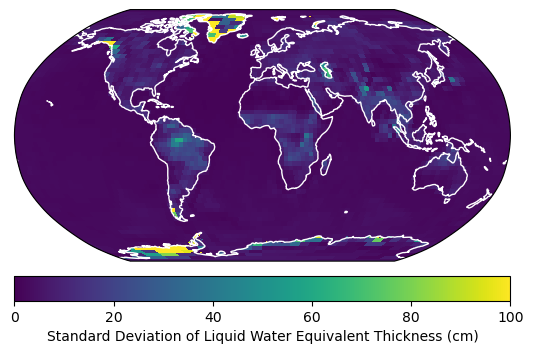

In [5]:
fig=plt.figure()
proj = ccrs.Robinson()
ax1 = fig.add_subplot(projection=proj)
C = ax1.pcolormesh(lon, lat, np.std(lwe_thickness[:,:,:],axis=0), transform=ccrs.PlateCarree(),
               vmin=0, vmax=100 ,cmap='viridis')
plt.colorbar(C, orientation='horizontal', pad=0.04,
             label='Standard Deviation of Liquid Water Equivalent Thickness (cm)')
ax1.coastlines(color='white')
plt.show()

**&#x1F914; Question for consideration**

After you've made your plot, consider the following question: Where is the variability the strongest? What do these locations have in common?

## Part 3: Masking Land Data and Visualizing Ocean Changes

To investigate changes in ocean mass, we'll need to remove the signal from land. One way to visualize this ocean signal alone is to mask out the portion on land. Since this is a common calculation, the GRACE team provides a land mask in the distributed mascon file. Make a plot of the land mask here:


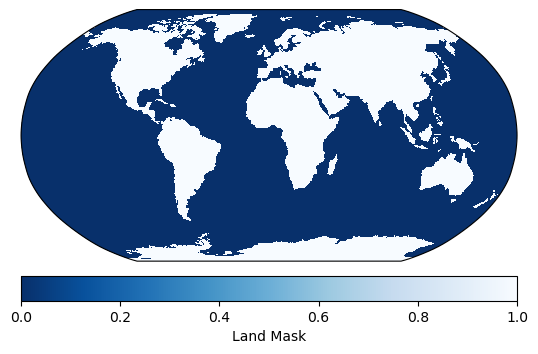

In [6]:
fig=plt.figure()
proj = ccrs.Robinson()
ax1 = fig.add_subplot(projection=proj)
C = ax1.pcolormesh(lon, lat, land_mask, transform=ccrs.PlateCarree(),
               vmin=0, vmax=1 ,cmap='Blues_r')
plt.colorbar(C, orientation='horizontal', pad=0.04, label='Land Mask')
plt.show()

The land mask can be applied to the data using numpy's `np.ma.masked_where` function. For example, the first time step of the mascon solution can be masked as follows:

```{code}
masked_lwe_thickness = np.ma.masked_where(land_mask==1, lwe_thickness[0,:,:])
```

Using this masking code, recreate your plot above with the land data masked out. Be sure to adjust your colorbar to be appropriate for the ocean-only data as needed.

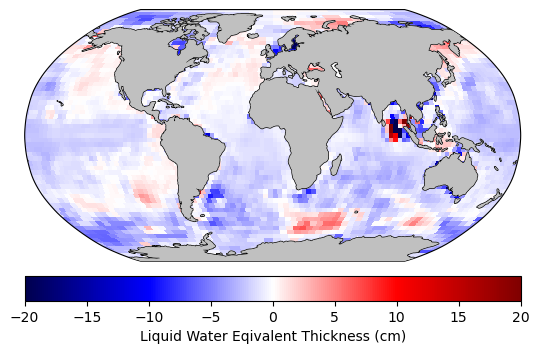

In [7]:
fig=plt.figure()
proj = ccrs.Robinson()
ax1 = fig.add_subplot(projection=proj)
masked_lwe_thickness = np.ma.masked_where(land_mask==1, lwe_thickness[0,:,:])
C = ax1.pcolormesh(lon, lat, masked_lwe_thickness, transform=ccrs.PlateCarree(),
               vmin=-20, vmax=20 ,cmap='seismic')
plt.colorbar(C, orientation='horizontal', pad=0.04, label='Liquid Water Eqivalent Thickness (cm)')
ax1.add_feature(cfeature.LAND, zorder=99, facecolor='silver')
ax1.coastlines(color='white')
ax1.coastlines(color='k')
plt.show()

**&#x1F914; Questions for consideration**

After you've made your plot, consider the following questions:
1. How does this change your assessment of ocean changes?
2. Try changing your time step to a new time period. What do you notice about the map? Why?

## Part 4: Computing Barystatic Sea Level Rise

Next, we will compute the area-weighted average liquid water equivalent thickness over the global ocean. This average tells us how much water would need to be spread evenly over the ocean to produce the same total volume anomaly -- in other words, barystatic sea level rise. Since the data are on a latitude-longitude grid, grid cells near the equator represent a larger area than grid cells near the poles. The first step in our calculation will be to estimate the area of each grid cell.

### Estimating grid cell areas
If we assume the Earth is a perfect sphere with radius $R=$6,371 km, it's fairly straightforward to compute the area of each cell if we think of each cell as taking up a given proportion of the sphere. On one hand, the area of a vertical latitude band between $\phi_1$ and $\phi_0$ has area

$$
A_{\text{Longitude Band}} = A_{Earth} \left(\frac{\phi_1 - \phi_0}{2\pi}\right)  = 2 R^2 (\phi_1 - \phi_0)
$$

Further, a little trigonometry shows the area of a portion of the sphere between the equator and a given latitude ($\theta$) is scaled by the *sin* of the latitude. Thus, in a given latitude band between $\theta_1$ and $\theta_0$, the fractional area is  

$$
A_{\text{Latitude Band}} = A_{Earth}\left(\frac{\sin (\theta_1) - \sin (\theta_0)}{2}\right)
$$

Putting these pieces together, we can compute the surface area of a given area of a sphere as 

$$
A_{patch} = R^2 (\phi_1 - \phi_0) (\sin (\theta_1) - \sin (\theta_0)) 
$$

Code this up below to make a 2D array of grid cell areas (Hint: be sure to use the longitude and latitude values at the grid cell edges rather than the centers):

In [8]:
# convert to radians
lon_bounds_rad = np.deg2rad(lon_bounds)
lat_bounds_rad = np.deg2rad(lat_bounds)

# make an array to store the area in each cell
R = 6371000
Area = np.zeros((len(lat), len(lon)))
for i in range(len(lon_bounds)):
    for j in range(len(lat_bounds)):
        Area[j,i] = R**2 * (lon_bounds_rad[i,1] - lon_bounds_rad[i,0]) * \
        (np.sin(lat_bounds_rad[j,1]) - np.sin(lat_bounds_rad[j,0])) 

### Computing Barystatic Sea Level Rise

With the area of each grid cell in hand, we're ready to compute the global barystatic sea level rise time series. The ocean volume anomaly at timestep $t$ is given by

$$
V_t = \sum_i^{I} \sum_j^{J} LWE_{i,j}A_{i,j}
$$

Here, $I$ and $J$ refer to the number of longitude and latitude values in the grid, $LWE_{i,j}$ is the gridded liquid water equivalent thickness in cell $(i,j)$, and $A_{i,j}$ is the area of that cell.

We can divide this by the total area of the ocean to get the thickness anomaly over the globe (barystatic sea level rise):

$$
L_t = \frac{\sum_i^{I} \sum_j^{J} LWE_{i,j}A_{i,j}}{\sum_i^{I} \sum_j^{J} A_{i,j}}
$$

Using this formula, compute the values at each timestep. Be sure to exclude the data over land!

In [9]:
# set the land areas to 0 in the area mask
Area[land_mask==1] = 0

# compute the thickness anomaly time series
barystatic_slr = np.zeros((np.shape(lwe_thickness)[0],))
for i in range(np.shape(lwe_thickness)[0]):
    barystatic_slr[i] = np.sum(lwe_thickness[i,:,:]*Area) / np.sum(Area)

### Computing Time
Before we plot the global ocean mass anomaly time series, we'll need to know what each time step corresponds to. When we read in the time, this was referenced in "days since 2002-01-01". That's a convenient time record for calculations, but our calendar-focused brains would be much better with data. In the space below, make a list called `dates` that converts each time step to a given date. The `datetime` package we read in earlier is quite useful for this calculation:

In [10]:
dates = []
for i in range(len(days_since_2002)):
    dates.append(datetime(2002,1,1) + timedelta(days = days_since_2002[i]))

### Plotting the Global Ocean Mass Anomaly Time Series

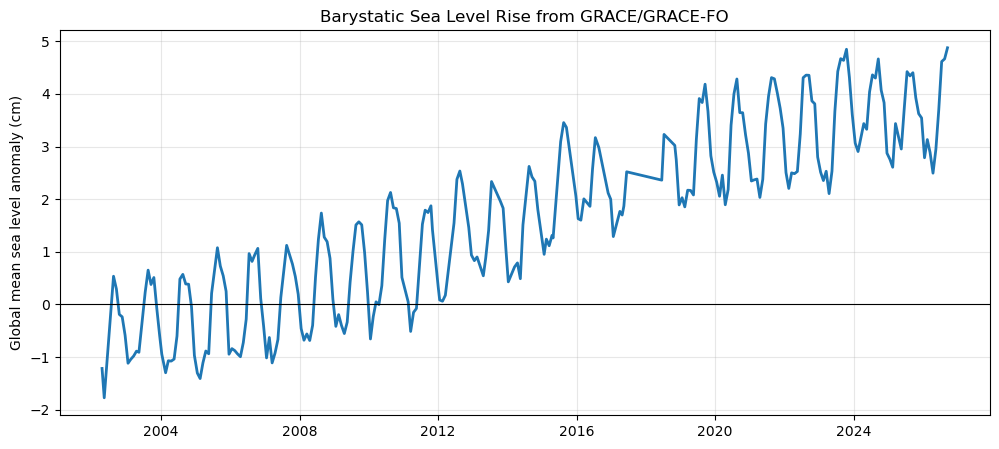

In [11]:
# Plot the global ocean mass time series with the dates
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(dates, barystatic_slr, '-', linewidth=2)
ax.axhline(0, color="k", linewidth=0.8)

ax.set_ylabel("Global mean sea level anomaly (cm)")
ax.set_title("Barystatic Sea Level Rise from GRACE/GRACE-FO")
ax.grid(alpha=0.3)

plt.show()

**&#x1F914; Questions for consideration**

1. Is there a long-term increase or decrease in ocean mass over the record?
2. What is the approximate range of the seasonal cycle? Why is there a seasonal cycle?
3. Are there any gaps in the time series? Why?

## Part 5: Estimating Steric Height

In the section above, we compute changes in ocean mass since the start of the GRACE observations. Next, we'll compare this record to that for global mean sea level as measured by radar altimeters to estimate changes in steric height.

### Download Mean Sea Surface Height Data

In Lab 10, we used sea surface height fields to estimate a time series of region or global mean sea level rise. Here, we will use a convenient product generated by JPL with this calculation already done. Navigate to the [NASA-SSH Global Mean Sea Level from Simple Gridded Sea Surface Height](https://podaac.jpl.nasa.gov/dataset/NASA_SSH_GMSL_INDICATOR) product page and download the most recent [NASA_SSH_GMSL_INDICATOR.txt](https://archive.podaac.earthdata.nasa.gov/podaac-ops-cumulus-protected/NASA_SSH_GMSL_INDICATOR/NASA_SSH_GMSL_INDICATOR.txt) document. (Hint: if you are on a Mac, you may need to right-click and choose "Save Link As...").  Be sure to put this in your data folder for this lab. 

After you've read in the data,read the data into a numpy array using the coding block below.

In [12]:
# read in the file here
global_mean_slr = np.genfromtxt(os.path.join(data_folder,'NASA_SSH_GMSL_INDICATOR.txt'),
                                delimiter='    ', skip_header=42)

Once you've read in the data, make a plot here:

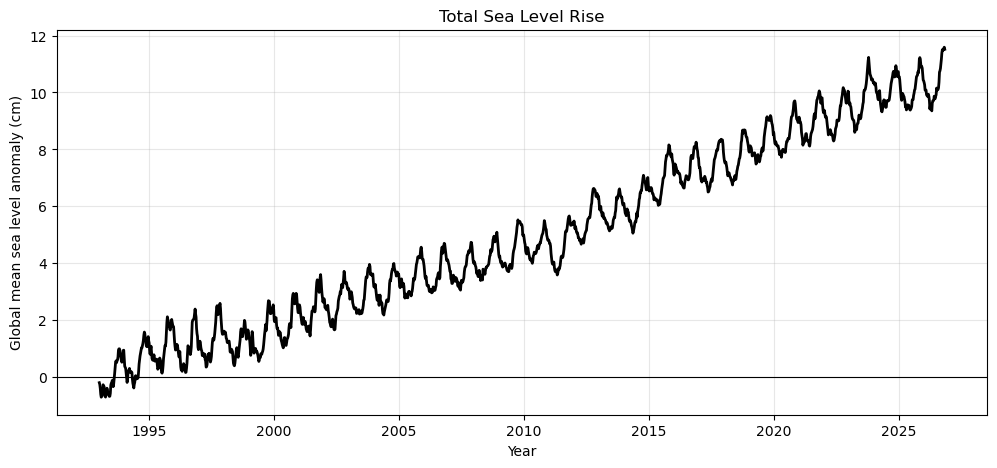

In [13]:
# Plot the global ocean mass time series
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(global_mean_slr[:,0], global_mean_slr[:,1], 'k-', linewidth=2)
ax.axhline(0, color="k", linewidth=0.8)

ax.set_xlabel("Year")
ax.set_ylabel("Global mean sea level anomaly (cm)")
ax.set_title("Total Sea Level Rise")
ax.grid(alpha=0.3)

plt.show()

**&#x1F914; Questions for consideration**

1. How does the time period of this record compare to the GRACE record?
2. What is the time step between observations? How does this compare to the GRACE record?
3. What are the units of time in this record? How does this compare to the GRACE record?
4. What is the anomaly in this record relative to? How does this compare to the GRACE record?

### Homogenize the time units across records

Clearly, the time series above has different time units and it represents a different length of time compared to the GRACE record. If we'd like to compare these and compute steric height as the residual from both time series, we need to have identical lengths and time records.

Use the space below to homogenize the time records and lengths of time. You can do this either by transforming the time coordinates of the GRACE record to the SSH record, or vice versa.

Here, we'll demo the latter process. To convert the SSH time record, first we'll define a function to convert a datetime `date` object to a decimal year:

In [14]:
def YMD_to_DecYr(date):
    
    start_of_year = datetime(date.year, 1, 1, 0, 0, 0)
    start_of_next_year = datetime(date.year + 1, 1, 1, 0, 0, 0)
    
    year_length = (start_of_next_year - start_of_year).total_seconds()
    seconds_into_year = (date - start_of_year).total_seconds()
    
    decimal_fraction = seconds_into_year / year_length
    dec_yr = date.year + decimal_fraction
    
    return dec_yr

Next, we'll use this function to find the record in the SSH time series that corresponds to the same month in the GRACE record.

In [15]:
# make a list to hold the homogenized values
total_slr_homogenized = []

# loop through each time record
for b in range(np.shape(days_since_2002_bounds)[0]):
    # identify the start and end date of the GRACE record
    start_date = datetime(2002,1,1) + timedelta(days = days_since_2002_bounds[b,0])
    end_date = datetime(2002,1,1) + timedelta(days = days_since_2002_bounds[b,1])
    
    # convert these to decimal years
    start_dec_yr = YMD_to_DecYr(datetime(start_date.year, start_date.month, start_date.day))
    end_dec_yr = YMD_to_DecYr(datetime(end_date.year, end_date.month, end_date.day))

    # find the indices corresponding to these records
    indices = np.logical_and(global_mean_slr[:,0]>=start_dec_yr, global_mean_slr[:,0]<end_dec_yr)
    if np.sum(indices)>0:
        total_slr_homogenized.append(np.mean(global_mean_slr[indices,1]))
    else:
        total_slr_homogenized.append(np.nan)

# make an array
total_slr_homogenized=np.array(total_slr_homogenized)

Now that the record is homogenized, plot the record to ensure it looks as expected:

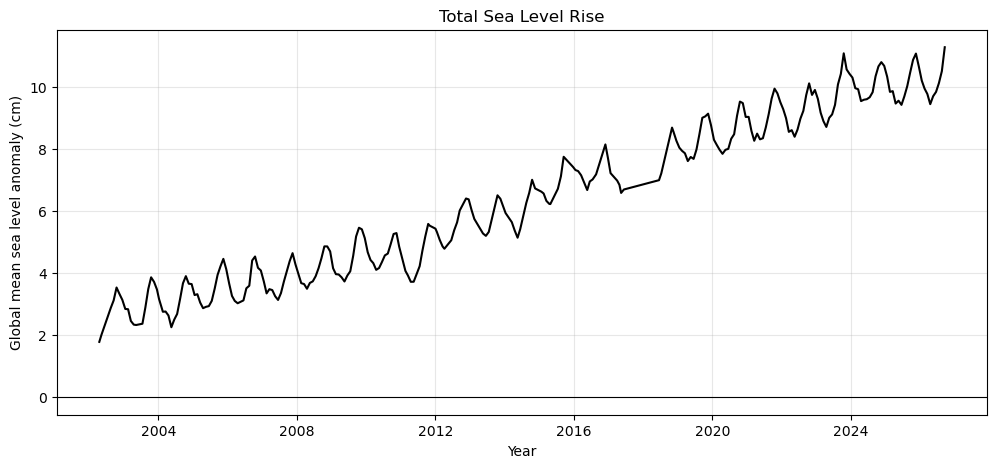

In [16]:
# Plot the global ocean mass time series
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(dates, total_slr_homogenized, 'k-', linewidth=1.5, )
ax.axhline(0, color="k", linewidth=0.8)

ax.set_xlabel("Year")
ax.set_ylabel("Global mean sea level anomaly (cm)")
ax.set_title("Total Sea Level Rise")
ax.grid(alpha=0.3)

plt.show()


### Computing Steric Height
Now that we've got our 

In [17]:
steric_height_anomaly = total_slr_homogenized - barystatic_slr

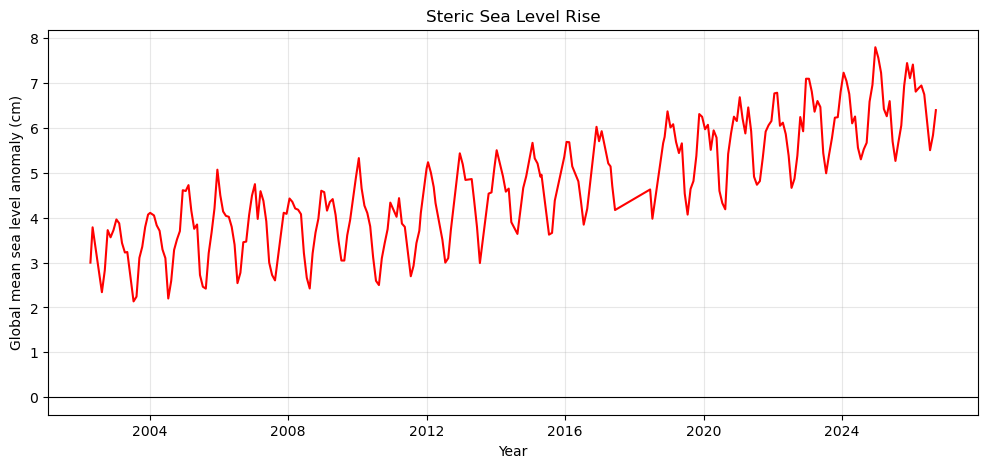

In [18]:
# Plot the global ocean mass time series
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(dates, steric_height_anomaly, 'r-', linewidth=1.5, )
ax.axhline(0, color="k", linewidth=0.8)

ax.set_xlabel("Year")
ax.set_ylabel("Global mean sea level anomaly (cm)")
ax.set_title("Steric Sea Level Rise")
ax.grid(alpha=0.3)

plt.show()


Now that we've isolated the steric height anomalies, remove the first value to reference all values to the height at the start of the GRACE record.

In [19]:
total_slr_homogenized -= total_slr_homogenized[0]
barystatic_slr -= barystatic_slr[0]
steric_height_anomaly -= steric_height_anomaly[0]

Finally, plot all records on the same plot:

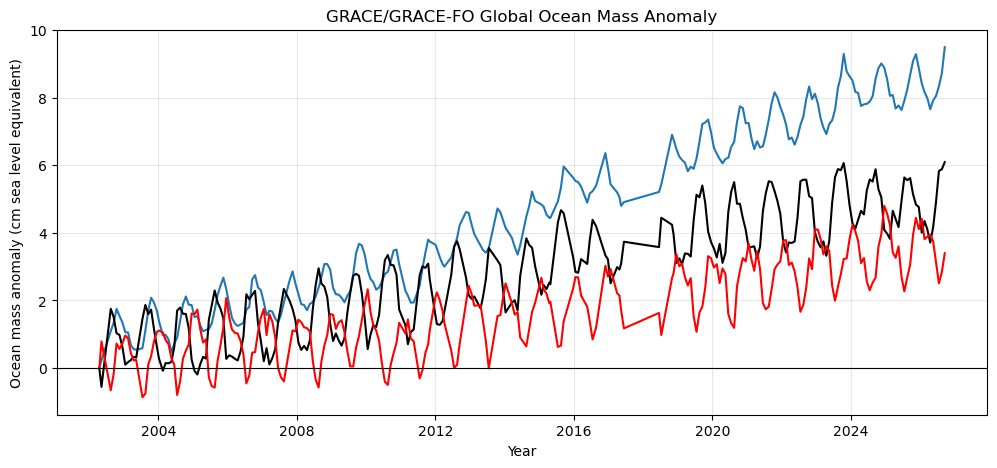

In [20]:
# Plot the global ocean mass time series
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(dates, total_slr_homogenized, '-', linewidth=1.5, )
ax.plot(dates, barystatic_slr, 'k-', linewidth=1.5, )
ax.plot(dates, steric_height_anomaly, 'r-', linewidth=1.5, )
ax.axhline(0, color="k", linewidth=0.8)

ax.set_xlabel("Year")
ax.set_ylabel("Ocean mass anomaly (cm sea level equivalent)")
ax.set_title("GRACE/GRACE-FO Global Ocean Mass Anomaly")
ax.grid(alpha=0.3)

plt.show()

**&#x1F914; Questions for consideration**

1. How does the steric height record compare to the barystatic height record?
2. What in situ observations might you use to corroborate your calculation of the steric height time series?